In [ ]:
!pip install -q gdown
import gdown
gdown.download("https://drive.google.com/file/d/1L7JtRWj4ts9NirJiZmWNWPNJRyKkUWD2/view?usp=sharing", "fraud_file", quiet=False, fuzzy=True)

Downloading...
From (original): https://drive.google.com/uc?id=1L7JtRWj4ts9NirJiZmWNWPNJRyKkUWD2
From (redirected): https://drive.google.com/uc?id=1L7JtRWj4ts9NirJiZmWNWPNJRyKkUWD2&confirm=t&uuid=49253948-0d2d-464e-b86b-074aa9437d95
To: /content/fraud_file
100%|██████████| 69.2M/69.2M [00:01<00:00, 49.4MB/s]


'fraud_file'

In [ ]:
!file fraud_file
!ls -lh fraud_file

fraud_file: Zip archive data, at least v4.5 to extract, compression method=deflate
-rw-r--r-- 1 root root 66M Nov 14 07:42 fraud_file


In [ ]:
import zipfile
with zipfile.ZipFile("fraud_file") as z:
    z.extractall("fraud_data")
    print(z.namelist())

!ls -lh fraud_data

['creditcard.csv']
total 144M
-rw-r--r-- 1 root root 144M Nov 23 21:33 creditcard.csv


In [ ]:
import pandas as pd
df = pd.read_csv("fraud_data/creditcard.csv")
print("Shape:", df.shape)
print(df.columns.tolist())
df.head()

Shape: (284807, 31)
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
df.info()
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [ ]:
print(df["Class"].value_counts())
print((df["Class"].value_counts(normalize=True) * 100).round(3))
print(df["Class"].unique())
df[["Time", "Amount"]].describe()

Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827
1     0.173
Name: proportion, dtype: float64
[0 1]


,Time,Amount
count,284807.000000,284807.000000
mean,94813.859575,88.349619
std,47488.145955,250.120109
min,0.000000,0.000000
25%,54201.500000,5.600000
50%,84692.000000,22.000000
75%,139320.500000,77.165000
max,172792.000000,25691.160000


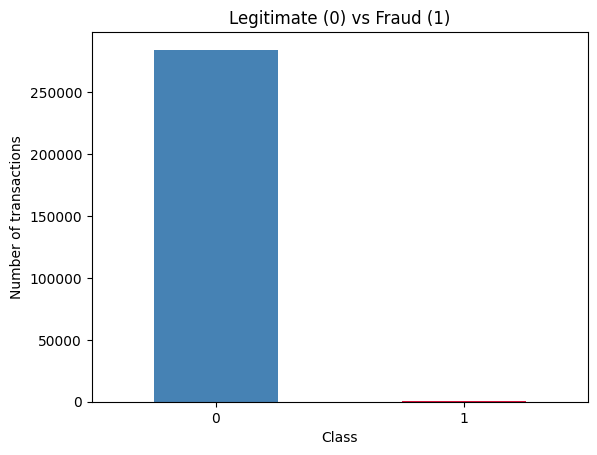

Class
0    1062
1      19
Name: count, dtype: int64


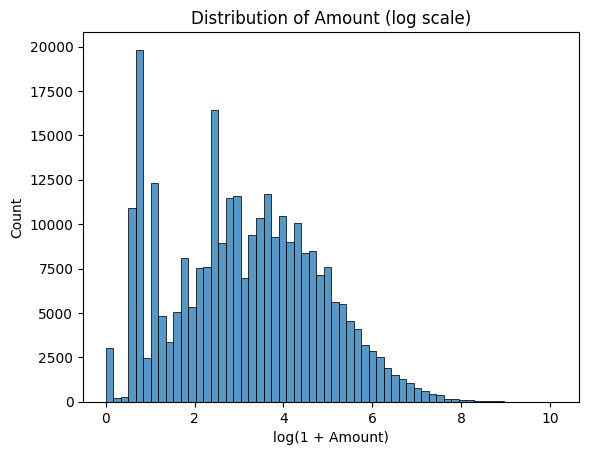

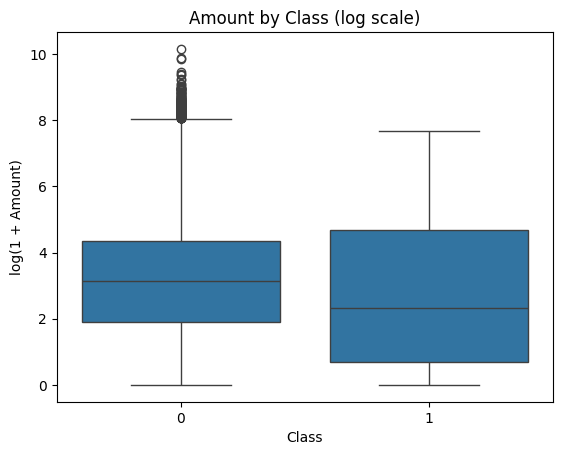

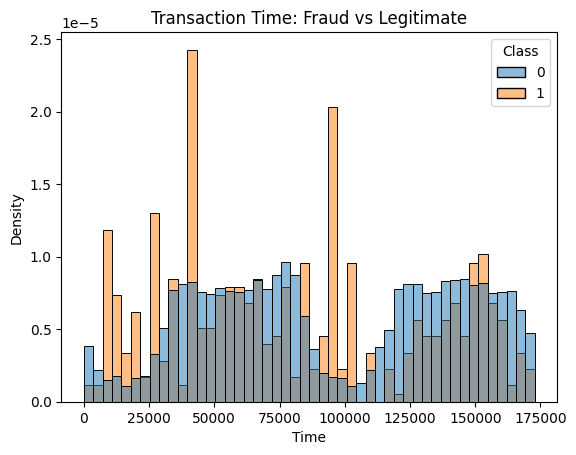

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Class distribution
df["Class"].value_counts().plot(kind="bar", color=["steelblue","crimson"], title="Legitimate (0) vs Fraud (1)")
plt.ylabel("Number of transactions"); plt.xticks(rotation=0); plt.show()

# 2. Duplicates by class
print(df[df.duplicated()]["Class"].value_counts())

# 3. Amount distribution (log scale, since it's skewed)
sns.histplot(np.log1p(df["Amount"]), bins=60)
plt.title("Distribution of Amount (log scale)"); plt.xlabel("log(1 + Amount)"); plt.show()

# 4. Amount by class
sns.boxplot(x="Class", y=np.log1p(df["Amount"]), data=df)
plt.title("Amount by Class (log scale)"); plt.ylabel("log(1 + Amount)"); plt.show()

# 5. Time by class
sns.histplot(data=df, x="Time", hue="Class", bins=48, stat="density", common_norm=False)
plt.title("Transaction Time: Fraud vs Legitimate"); plt.show()

# 6. Amount statistics by class
print(df.groupby("Class")["Amount"].describe().round(2))

Class
0    1062
1      19
Name: count, dtype: int64


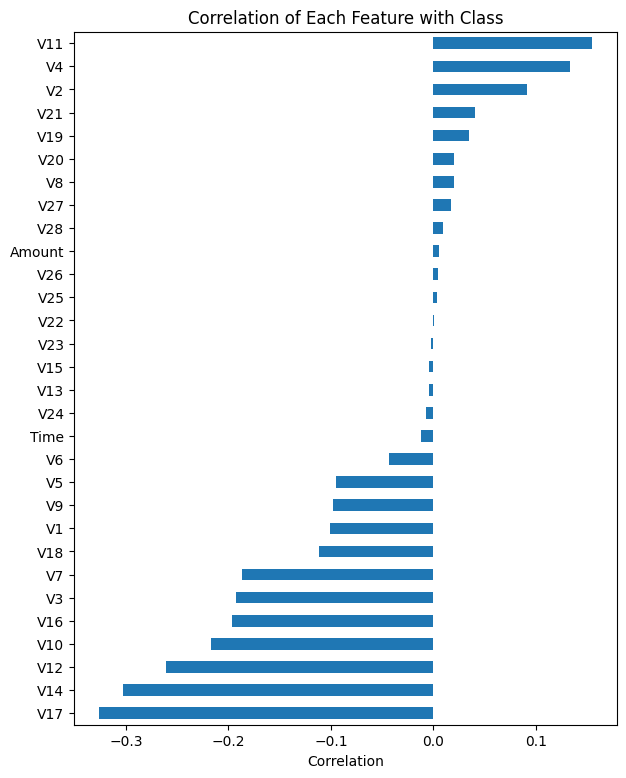

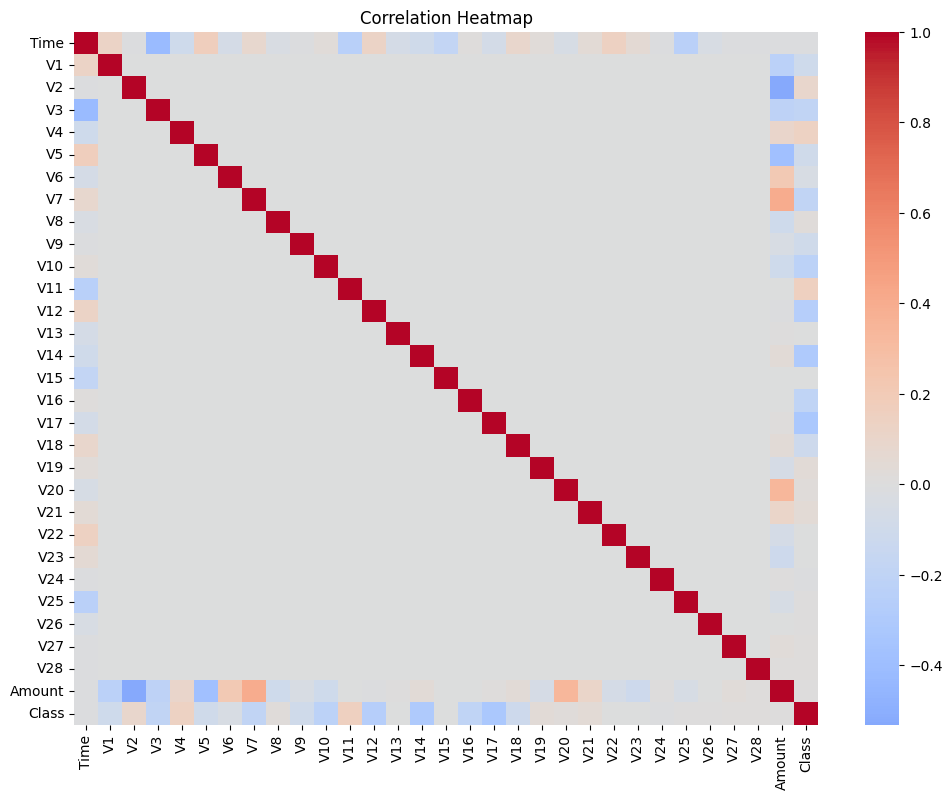

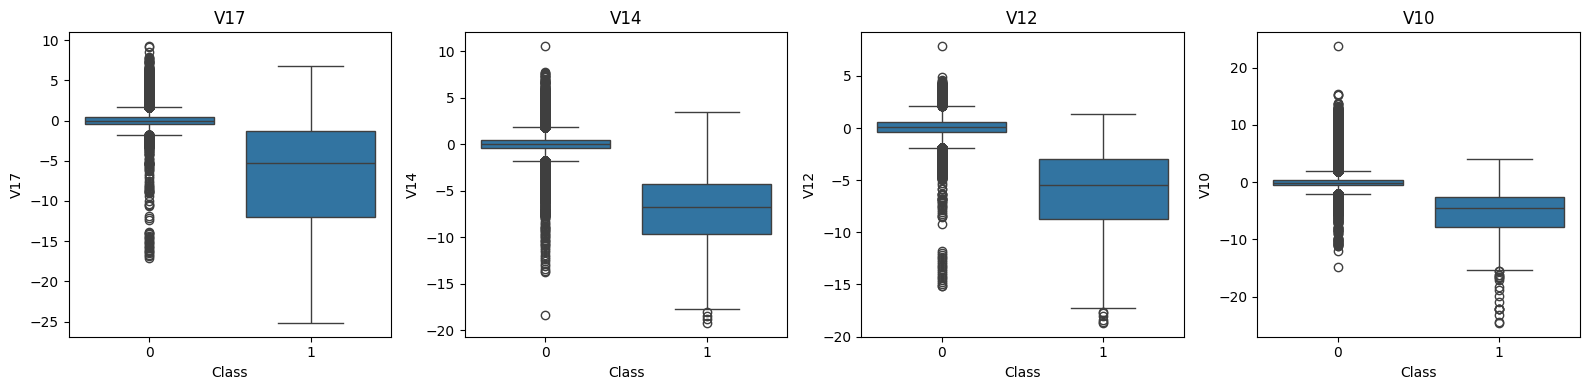

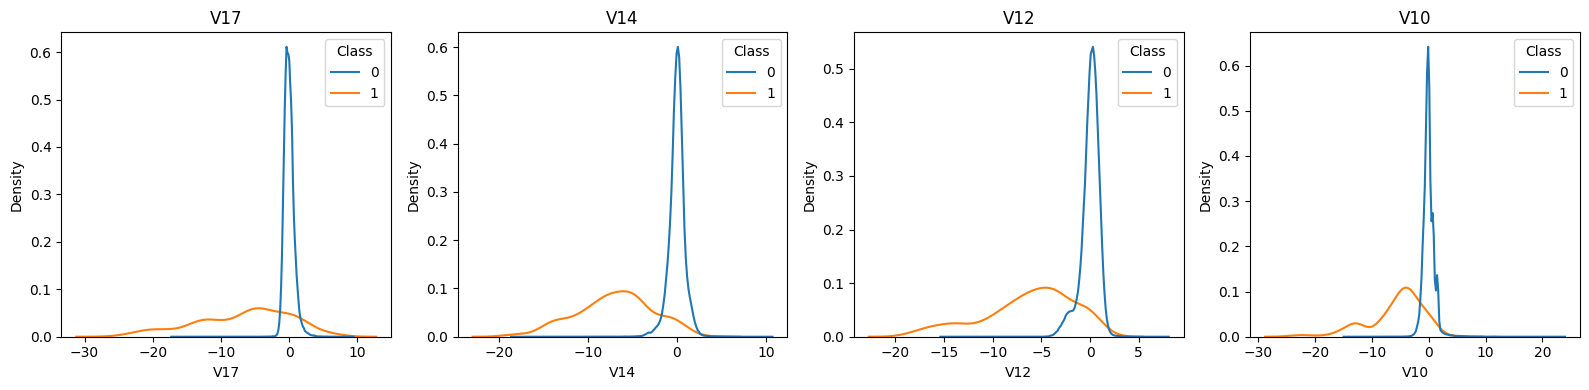

['V17', 'V14', 'V12', 'V10']


In [ ]:
# 1. Duplicates by class (send me this output)
print(df[df.duplicated()]["Class"].value_counts())

# 2. Which features are linked to fraud
corr = df.corr()["Class"].drop("Class").sort_values()
corr.plot(kind="barh", figsize=(7,9), title="Correlation of Each Feature with Class")
plt.xlabel("Correlation"); plt.show()

# 3. Correlation heatmap
plt.figure(figsize=(12,9))
sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap"); plt.show()

# 4. Boxplots of the 4 features most linked to Class
top = df.corr()["Class"].drop("Class").abs().sort_values(ascending=False).head(4).index
fig, axes = plt.subplots(1, 4, figsize=(16,4))
for ax, col in zip(axes, top):
    sns.boxplot(x="Class", y=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

# 5. Density plots of the same 4 features
fig, axes = plt.subplots(1, 4, figsize=(16,4))
for ax, col in zip(axes, top):
    sns.kdeplot(data=df, x=col, hue="Class", common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()
print(list(top))

In [ ]:
# Duplicates by class
print("Duplicates by class:")
print(df[df.duplicated()]["Class"].value_counts())

# Remove duplicates BEFORE splitting
df_clean = df.drop_duplicates().reset_index(drop=True)
print("\nShape before:", df.shape)
print("Shape after:", df_clean.shape)
print("\nClass counts after:")
print(df_clean["Class"].value_counts())
print((df_clean["Class"].value_counts(normalize=True) * 100).round(3))

Duplicates by class:
Class
0    1062
1      19
Name: count, dtype: int64

Shape before: (284807, 31)
Shape after: (283726, 31)

Class counts after:
Class
0    283253
1       473
Name: count, dtype: int64
Class
0    99.833
1     0.167
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.compose import ColumnTransformer

# 1. Separate features (X) and target (y)
X = df_clean.drop("Class", axis=1)
y = df_clean["Class"]

# 2. Stratified split: keeps the same fraud ratio in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nFraud % in train:", round(y_train.mean() * 100, 3))
print("Fraud % in test: ", round(y_test.mean() * 100, 3))
print("\nFraud count in train:", y_train.sum(), "| in test:", y_test.sum())

# 3. Preprocessor: scale only Time and Amount, leave V1-V28 unchanged
preprocessor = ColumnTransformer(
    transformers=[("scale", RobustScaler(), ["Time", "Amount"])],
    remainder="passthrough"
)

# Fit on TRAIN only, then apply to test (prevents data leakage)
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)
print("\nProcessed shapes:", X_train_p.shape, X_test_p.shape)

Train: (226980, 30) | Test: (56746, 30)

Fraud % in train: 0.167
Fraud % in test:  0.167

Fraud count in train: 378 | in test: 95

Processed shapes: (226980, 30) (56746, 30)


Training class counts after resampling:
Original:     {0: 226602, 1: 378}
Undersample:  {0: 378, 1: 378}
Oversample:   {0: 226602, 1: 226602}
SMOTE:        {0: 226602, 1: 226602}

                Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC
Method                                                             
No handling      0.9992     0.8615  0.5895  0.7000   0.9575  0.6951
Class weight     0.9752     0.0562  0.8737  0.1057   0.9657  0.6719
Undersampling    0.9724     0.0508  0.8737  0.0960   0.9554  0.6004
Oversampling     0.9755     0.0569  0.8737  0.1068   0.9660  0.6719
SMOTE            0.9740     0.0537  0.8737  0.1012   0.9600  0.6729


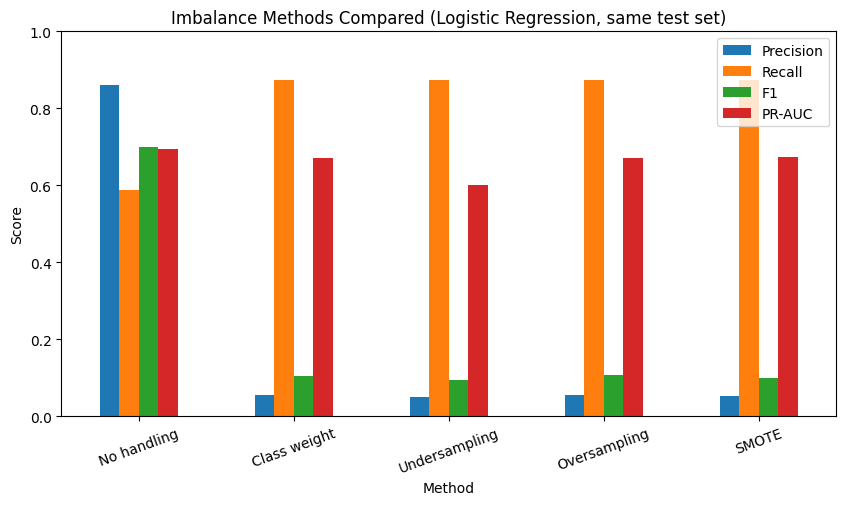

In [ ]:
!pip install -q imbalanced-learn

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

def run(name, model, Xtr, ytr):
    model.fit(Xtr, ytr)
    pred = model.predict(X_test_p)
    prob = model.predict_proba(X_test_p)[:, 1]
    return {
        "Method": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "PR-AUC": average_precision_score(y_test, prob),
    }

def lr(**kw):
    return LogisticRegression(max_iter=1000, random_state=42, **kw)

# Resample the TRAINING data only
X_us, y_us = RandomUnderSampler(random_state=42).fit_resample(X_train_p, y_train)
X_os, y_os = RandomOverSampler(random_state=42).fit_resample(X_train_p, y_train)
X_sm, y_sm = SMOTE(random_state=42).fit_resample(X_train_p, y_train)

print("Training class counts after resampling:")
print("Original:    ", y_train.value_counts().to_dict())
print("Undersample: ", y_us.value_counts().to_dict())
print("Oversample:  ", y_os.value_counts().to_dict())
print("SMOTE:       ", y_sm.value_counts().to_dict())

results = [
    run("No handling", lr(), X_train_p, y_train),
    run("Class weight", lr(class_weight="balanced"), X_train_p, y_train),
    run("Undersampling", lr(), X_us, y_us),
    run("Oversampling", lr(), X_os, y_os),
    run("SMOTE", lr(), X_sm, y_sm),
]

res = pd.DataFrame(results).set_index("Method").round(4)
print("\n", res)

res[["Precision", "Recall", "F1", "PR-AUC"]].plot(kind="bar", figsize=(10, 5),
    title="Imbalance Methods Compared (Logistic Regression, same test set)")
plt.ylabel("Score"); plt.xticks(rotation=20); plt.ylim(0, 1); plt.show()

In [ ]:
import time
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

spw = (y_train == 0).sum() / (y_train == 1).sum()

def make_models(weighted):
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42,
            class_weight="balanced" if weighted else None),
        "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12,
            n_jobs=-1, random_state=42,
            class_weight="balanced_subsample" if weighted else None),
        "XGBoost": XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
            eval_metric="logloss", n_jobs=-1, random_state=42,
            scale_pos_weight=spw if weighted else 1),
    }

strategies = {
    "No handling": (X_train_p, y_train, False),
    "Class weight": (X_train_p, y_train, True),
    "SMOTE": (X_sm, y_sm, False),
}

all_results, fitted = [], {}
for strat, (Xtr, ytr, weighted) in strategies.items():
    for name, model in make_models(weighted).items():
        t = time.time()
        all_results.append(run(f"{name} | {strat}", model, Xtr, ytr))
        fitted[(name, strat)] = model
        print(f"done: {name} | {strat} ({time.time()-t:.0f}s)")

comparison = pd.DataFrame(all_results).set_index("Method").round(4)
print(comparison.sort_values("PR-AUC", ascending=False))

done: Logistic Regression | No handling (5s)
done: Random Forest | No handling (236s)
done: XGBoost | No handling (9s)
done: Logistic Regression | Class weight (4s)
done: Random Forest | Class weight (155s)
done: XGBoost | Class weight (8s)
done: Logistic Regression | SMOTE (8s)
done: Random Forest | SMOTE (396s)
done: XGBoost | SMOTE (14s)
                                    Accuracy  Precision  Recall      F1  \
Method                                                                    
XGBoost | SMOTE                       0.9973     0.3641  0.8316  0.5064   
XGBoost | Class weight                0.9992     0.7379  0.8000  0.7677   
XGBoost | No handling                 0.9995     0.9571  0.7053  0.8121   
Random Forest | SMOTE                 0.9990     0.6881  0.7895  0.7353   
Random Forest | Class weight          0.9994     0.8861  0.7368  0.8046   
Random Forest | No handling           0.9995     0.9857  0.7263  0.8364   
Logistic Regression | No handling     0.9992     0.8615  

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 6],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "min_child_weight": [1, 3, 5],
}

search = RandomizedSearchCV(
    XGBClassifier(eval_metric="logloss", n_jobs=-1, random_state=42,
                  scale_pos_weight=spw),
    param_distributions=param_dist,
    n_iter=12, cv=StratifiedKFold(3, shuffle=True, random_state=42),
    scoring="average_precision", random_state=42, n_jobs=1, verbose=1
)
search.fit(X_train_p, y_train)

print("Best settings:", search.best_params_)
print("Best CV PR-AUC (train only):", round(search.best_score_, 4))

tuned = run("XGBoost tuned | Class weight", search.best_estimator_, X_train_p, y_train)
print(pd.DataFrame([tuned]).set_index("Method").round(4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best settings: {'subsample': 0.85, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
Best CV PR-AUC (train only): 0.8467
                              Accuracy  Precision  Recall      F1  ROC-AUC  \
Method                                                                       
XGBoost tuned | Class weight    0.9995     0.9367  0.7789  0.8506   0.9775   

                              PR-AUC  
Method                                
XGBoost tuned | Class weight  0.8388  


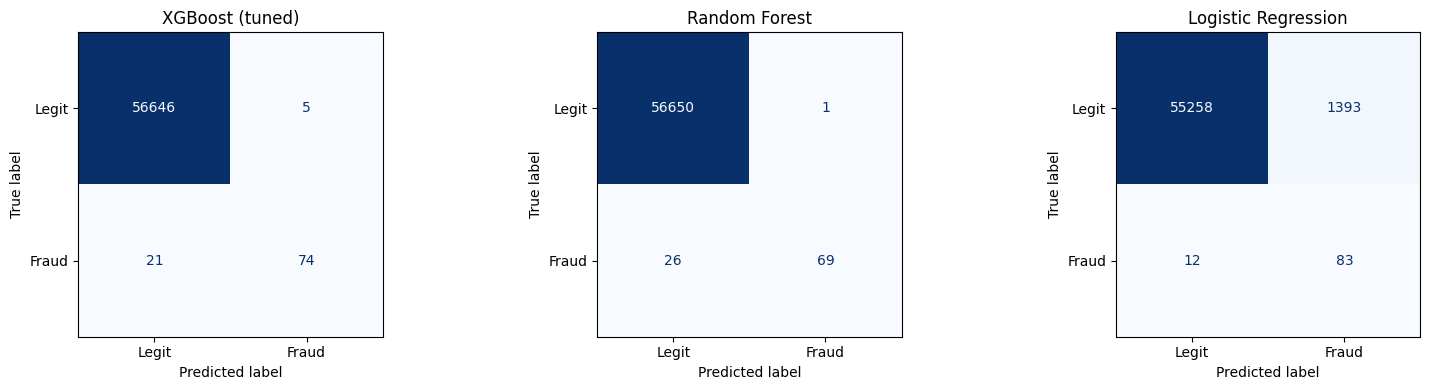

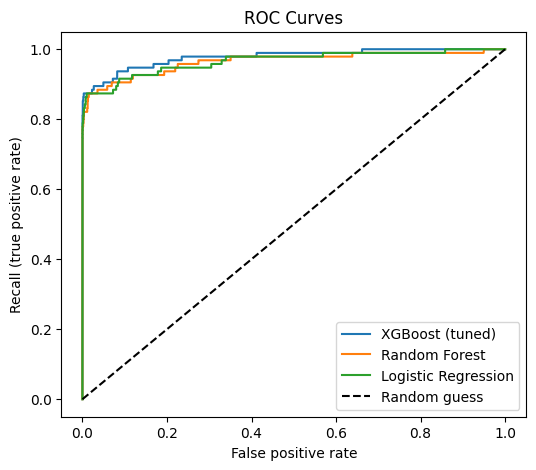

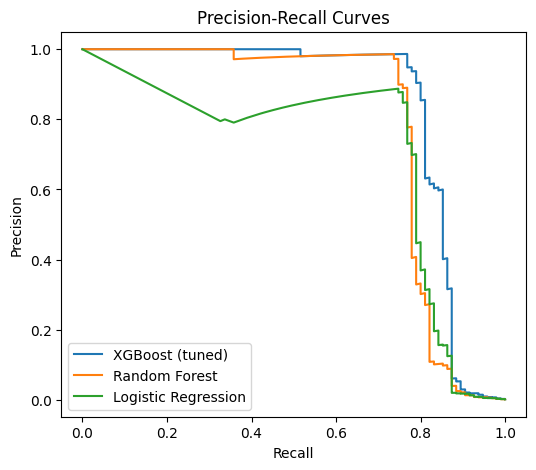

                     Accuracy  Precision  Recall      F1  ROC-AUC  PR-AUC  \
Model                                                                       
XGBoost (tuned)        0.9995     0.9367  0.7789  0.8506   0.9775  0.8388   
Random Forest          0.9995     0.9857  0.7263  0.8364   0.9650  0.7875   
Logistic Regression    0.9752     0.0562  0.8737  0.1057   0.9657  0.6719   

                     Frauds caught  Frauds missed  False alarms  
Model                                                            
XGBoost (tuned)                 74             21             5  
Random Forest                   69             26             1  
Logistic Regression             83             12          1393  
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.94      0.78      0.85        95

    accuracy                           1.00     56746
   macro avg       0.97      0.89      0.93     56746
weighted avg

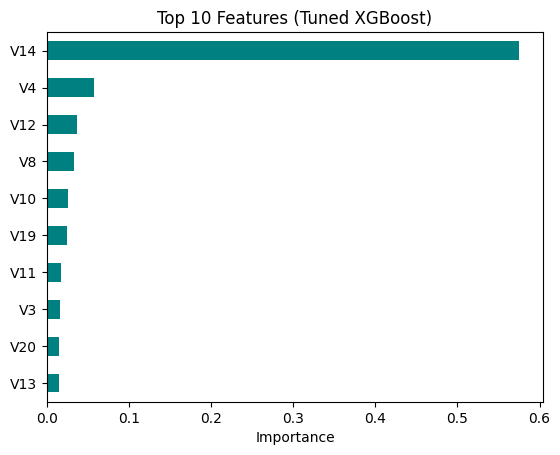

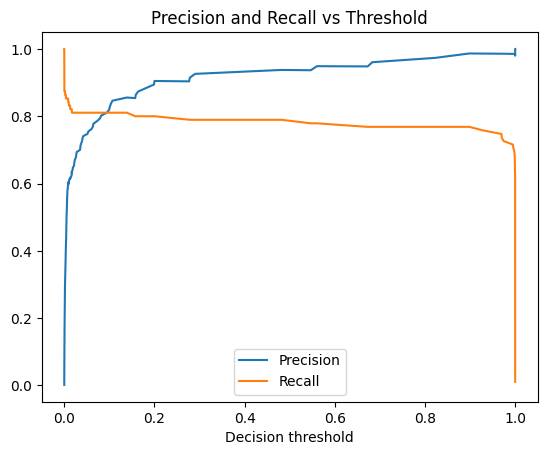

In [ ]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             precision_recall_curve, classification_report)

final_models = {
    "XGBoost (tuned)": search.best_estimator_,
    "Random Forest": fitted[("Random Forest", "No handling")],
    "Logistic Regression": fitted[("Logistic Regression", "Class weight")],
}

# 1. Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, m) in zip(axes, final_models.items()):
    cm = confusion_matrix(y_test, m.predict(X_test_p))
    ConfusionMatrixDisplay(cm, display_labels=["Legit", "Fraud"]).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

# 2. ROC curves
plt.figure(figsize=(6, 5))
for name, m in final_models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test_p)[:, 1])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate"); plt.ylabel("Recall (true positive rate)")
plt.title("ROC Curves"); plt.legend(); plt.show()

# 3. Precision-Recall curves
plt.figure(figsize=(6, 5))
for name, m in final_models.items():
    p, r, _ = precision_recall_curve(y_test, m.predict_proba(X_test_p)[:, 1])
    plt.plot(r, p, label=name)
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall Curves"); plt.legend(); plt.show()

# 4. Final comparison table
rows = []
for name, m in final_models.items():
    pred = m.predict(X_test_p); prob = m.predict_proba(X_test_p)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, prob),
                 "PR-AUC": average_precision_score(y_test, prob),
                 "Frauds caught": tp, "Frauds missed": fn, "False alarms": fp})
print(pd.DataFrame(rows).set_index("Model").round(4))

# 5. Classification report for the tuned model
best = search.best_estimator_
print(classification_report(y_test, best.predict(X_test_p), target_names=["Legitimate", "Fraud"]))

# 6. Top 10 most important features (tuned XGBoost)
names = ["Time", "Amount"] + [c for c in X_train.columns if c not in ["Time", "Amount"]]
imp = pd.Series(best.feature_importances_, index=names).sort_values().tail(10)
imp.plot(kind="barh", title="Top 10 Features (Tuned XGBoost)", color="teal")
plt.xlabel("Importance"); plt.show()

# 7. Precision and recall at different thresholds (tuned XGBoost)
p, r, t = precision_recall_curve(y_test, best.predict_proba(X_test_p)[:, 1])
plt.plot(t, p[:-1], label="Precision"); plt.plot(t, r[:-1], label="Recall")
plt.xlabel("Decision threshold"); plt.title("Precision and Recall vs Threshold")
plt.legend(); plt.show()

In [ ]:
import joblib, os, json
os.makedirs("models", exist_ok=True)
joblib.dump(preprocessor, "models/preprocessor.joblib")
joblib.dump(best, "models/xgboost_tuned.joblib")
json.dump(list(X_train.columns), open("models/feature_order.json", "w"))
json.dump(search.best_params_, open("models/best_params.json", "w"))
pd.DataFrame(rows).set_index("Model").round(4).to_csv("models/final_results.csv")
print(os.listdir("models"))

['preprocessor.joblib', 'xgboost_tuned.joblib', 'final_results.csv', 'best_params.json', 'feature_order.json']


In [1]:
import numpy, pandas, sklearn, xgboost, imblearn, matplotlib, seaborn, joblib
for name, m in [("numpy", numpy), ("pandas", pandas), ("scikit-learn", sklearn),
                ("xgboost", xgboost), ("imbalanced-learn", imblearn),
                ("matplotlib", matplotlib), ("seaborn", seaborn), ("joblib", joblib)]:
    print(f"{name}=={m.__version__}")

numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
xgboost==3.4.1
imbalanced-learn==0.14.2
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.6.0
